In [7]:
import sys
from pathlib import Path

import duckdb
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
GOLD_DB = PROJECT_ROOT / "data" / "gold" / "fraud_dev.duckdb"


def q(sql: str) -> pd.DataFrame:
    """Run one query on Gold (read-only) and close the connection."""
    with duckdb.connect(str(GOLD_DB), read_only=True) as con:
        return con.sql(sql).df()


print("Gold file exists:", GOLD_DB.exists())
print("duckdb version:", duckdb.__version__)

tables = q("""
    select table_schema, table_name, table_type
    from information_schema.tables
    order by table_schema, table_name
""")
tables

Gold file exists: True
duckdb version: 1.5.6


,table_schema,table_name,table_type
0,main,category_mcc_map,BASE TABLE
1,main,dim_card,BASE TABLE
2,main,dim_date,BASE TABLE
3,main,dim_location,BASE TABLE
4,main,dim_merchant,BASE TABLE
5,main,fact_transactions,BASE TABLE
6,main,int_state_public_holidays,VIEW
7,main,stg_census_acs,VIEW
8,main,stg_census_zcta,VIEW
9,main,stg_holidays,VIEW


In [4]:
checks = q("""
    select 'fact_transactions' as table_name,
           count(*) as n_rows,
           sum(is_fraud) as n_fraud,
           count(distinct trans_num) as n_distinct_key,
           min(trans_ts)::varchar as first_value,
           max(trans_ts)::varchar as last_value
    from fact_transactions
    union all
    select 'dim_card', count(*), null, count(distinct card_key), null, null
    from dim_card
    union all
    select 'dim_merchant', count(*), null, count(distinct merchant_key), null, null
    from dim_merchant
    union all
    select 'dim_location', count(*), null, count(distinct location_key), null, null
    from dim_location
    union all
    select 'dim_date', count(*), null, count(distinct date_key),
           min(date_key)::varchar, max(date_key)::varchar
    from dim_date
""")
checks

,table_name,n_rows,n_fraud,n_distinct_key,first_value,last_value
0,fact_transactions,1852394,9651.0,1852394,2019-01-01 00:00:18,2020-12-31 23:59:34
1,dim_card,999,NaN,999,NaN,NaN
2,dim_merchant,700,NaN,700,NaN,NaN
3,dim_location,985,NaN,985,NaN,NaN
4,dim_date,731,NaN,731,20190101,20201231


In [5]:
df = q("""
    select f.trans_num, f.card_key, f.trans_ts, f.amt, f.is_fraud,
           f.distance_km, f.is_public_holiday_in_state,
           m.category, m.mcc, m.channel,
           c.gender, year(f.trans_ts) - c.birth_year as age,
           l.state, l.city_pop, l.population,
           l.median_household_income, l.has_income,
           d.is_nationwide_public_holiday, d.is_bank_holiday,
           hour(f.trans_ts) as hour,
           isodow(f.trans_ts) as day_of_week
    from fact_transactions f
    join dim_merchant m using (merchant_key)
    join dim_card     c using (card_key)
    join dim_location l using (location_key)
    join dim_date     d using (date_key)
    order by f.trans_ts
""")

for col in ["category", "channel", "gender", "state"]:
    df[col] = df[col].astype("category")

df["is_public_holiday"] = (
    df["is_nationwide_public_holiday"].astype(bool)
    | df["is_public_holiday_in_state"].astype(bool)
)

print("rows:", len(df))
print("fraud:", int(df["is_fraud"].sum()))
print("public holiday rows:", int(df["is_public_holiday"].sum()))
print("memory MB:", round(df.memory_usage(deep=True).sum() / 1e6))
df.head()

rows: 1852394
fraud: 9651
public holiday rows: 52496
memory MB: 324


,trans_num,card_key,trans_ts,amt,is_fraud,distance_km,is_public_holiday_in_state,category,mcc,channel,...,state,city_pop,population,median_household_income,has_income,is_nationwide_public_holiday,is_bank_holiday,hour,day_of_week,is_public_holiday
0,0b242abb623afc578575680df30655b9,53d05b61e5072bdf3dab95b88d962b79,2019-01-01 00:00:18,4.97,0,78.598,True,misc_net,5999,online,...,NC,3495,3268,45809,True,True,True,0,2,True
1,1f76529f8574734946361c461b024d99,dda80a24691174ae5baac184999faf5d,2019-01-01 00:00:44,107.23,0,30.212,True,grocery_pos,5411,in_person,...,WA,149,112,22500,True,True,True,0,2,True
2,a1a22d70485983eac12b5b88dad1cf95,b5922d2b151a76bf2c666217a38137eb,2019-01-01 00:00:51,220.11,0,108.206,True,entertainment,7999,unknown,...,ID,4154,4343,53636,True,True,True,0,2,True
3,6b849c168bdad6f867558c3793159a81,89d00840eb13328b06757e15313547c8,2019-01-01 00:01:16,45.00,0,95.673,True,gas_transport,5541,unknown,...,MT,1939,1488,44063,True,True,True,0,2,True
4,a41d7549acf90789359a9aa5346dcb46,dd990036f34cf06683da573e1833aa3a,2019-01-01 00:03:06,41.96,0,77.557,True,misc_pos,5999,in_person,...,VA,99,73,47813,True,True,True,0,2,True


overall fraud rate: 0.521%
              count    mean     std   min     25%     50%     75%      99%  \
is_fraud                                                                     
0         1842743.0   67.65  153.55  1.00    9.61   47.24   82.56   484.91   
1            9651.0  530.66  391.03  1.06  240.08  390.00  902.36  1175.85   

               max  
is_fraud            
0         28948.90  
1          1376.04  


,amt_min,amt_max,n,fraud,rate_pct,ci_low_pct,ci_high_pct,lift
amt_decile,,,,,,,,
1,1.00,4.10,185394,22,0.012,0.008,0.018,0.023
2,4.11,7.74,185457,196,0.106,0.092,0.122,0.203
3,7.75,15.72,184871,907,0.491,0.460,0.524,0.942
4,15.73,32.08,185247,884,0.477,0.447,0.510,0.916
5,32.09,47.45,185314,6,0.003,0.001,0.007,0.006
6,47.46,60.91,185212,108,0.058,0.048,0.070,0.112
7,60.92,75.01,185275,0,0.000,0.000,0.002,0.000
8,75.02,94.59,185155,2,0.001,0.000,0.004,0.002
9,94.60,136.33,185237,177,0.096,0.082,0.111,0.183


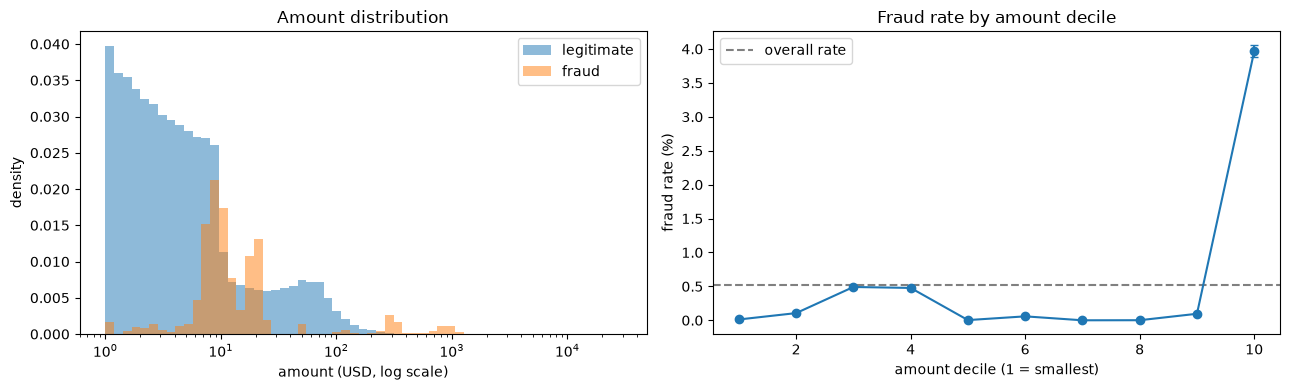

In [8]:
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

BASE_RATE = df["is_fraud"].mean()
print(f"overall fraud rate: {BASE_RATE:.3%}")


def rate_table(data: pd.DataFrame, by) -> pd.DataFrame:
    """Fraud rate per group with Wilson 95% CI and lift vs the base rate."""
    t = data.groupby(by, observed=True).agg(
        n=("is_fraud", "size"),
        fraud=("is_fraud", "sum"),
    )
    t["rate_pct"] = 100 * t["fraud"] / t["n"]
    low, high = proportion_confint(t["fraud"], t["n"], method="wilson")
    t["ci_low_pct"] = 100 * low
    t["ci_high_pct"] = 100 * high
    t["lift"] = (t["fraud"] / t["n"]) / BASE_RATE
    return t.round(3)


# 1) amount distribution, fraud vs legitimate
print(
    df.groupby("is_fraud")["amt"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.99])
    .round(2)
)

# 2) fraud rate per amount decile
df["amt_decile"] = pd.qcut(df["amt"], q=10, labels=False) + 1
amt_range = df.groupby("amt_decile")["amt"].agg(amt_min="min", amt_max="max")
by_decile = amt_range.join(rate_table(df, "amt_decile"))
display(by_decile)

# 3) plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

bins = np.logspace(0, np.log10(df["amt"].max()), 60)
for label, part in df.groupby("is_fraud"):
    axes[0].hist(part["amt"], bins=bins, density=True, alpha=0.5,
                 label="fraud" if label == 1 else "legitimate")
axes[0].set_xscale("log")
axes[0].set_xlabel("amount (USD, log scale)")
axes[0].set_ylabel("density")
axes[0].set_title("Amount distribution")
axes[0].legend()

axes[1].errorbar(
    by_decile.index, by_decile["rate_pct"],
    yerr=[by_decile["rate_pct"] - by_decile["ci_low_pct"],
          by_decile["ci_high_pct"] - by_decile["rate_pct"]],
    marker="o", capsize=3,
)
axes[1].axhline(100 * BASE_RATE, linestyle="--", color="grey", label="overall rate")
axes[1].set_xlabel("amount decile (1 = smallest)")
axes[1].set_ylabel("fraud rate (%)")
axes[1].set_title("Fraud rate by amount decile")
axes[1].legend()

plt.tight_layout()
plt.show()

,n,fraud,rate_pct,ci_low_pct,ci_high_pct,lift
hour,,,,,,
0,60655,823,1.357,1.268,1.452,2.604
1,61330,827,1.348,1.260,1.443,2.588
2,60796,793,1.304,1.217,1.398,2.504
3,60968,803,1.317,1.230,1.411,2.528
4,59938,61,0.102,0.079,0.131,0.195
5,60088,80,0.133,0.107,0.166,0.256
6,60406,54,0.089,0.069,0.117,0.172
7,60301,72,0.119,0.095,0.150,0.229
8,60498,59,0.098,0.076,0.126,0.187


,n,fraud,rate_pct,ci_low_pct,ci_high_pct,lift
day_of_week,,,,,,
1,369418,1484,0.402,0.382,0.423,0.771
2,270340,1266,0.468,0.443,0.495,0.899
3,183913,1125,0.612,0.577,0.648,1.174
4,206741,1317,0.637,0.604,0.672,1.223
5,215078,1376,0.640,0.607,0.674,1.228
6,263227,1493,0.567,0.539,0.597,1.089
7,343677,1590,0.463,0.441,0.486,0.888


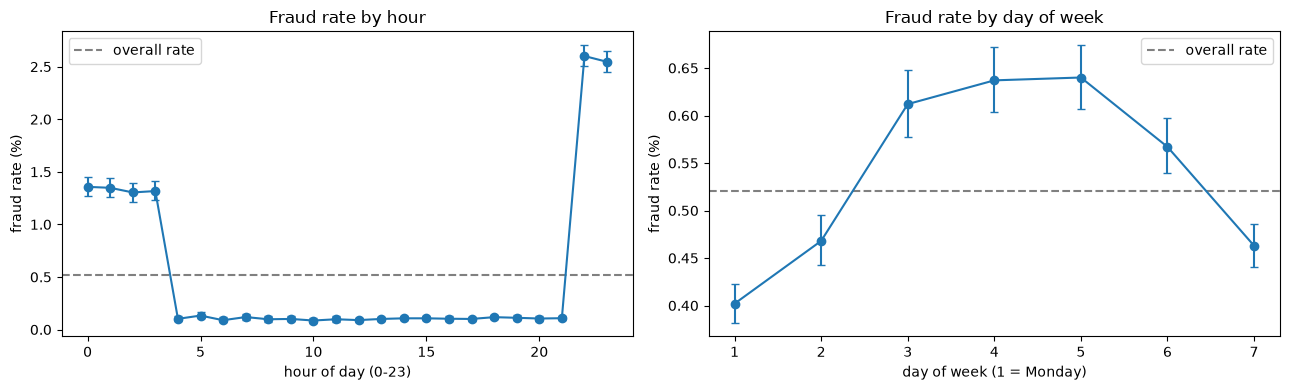

In [9]:
by_hour = rate_table(df, "hour")
by_dow = rate_table(df, "day_of_week")
display(by_hour)
display(by_dow)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
panels = [
    (axes[0], by_hour, "hour of day (0-23)", "Fraud rate by hour"),
    (axes[1], by_dow, "day of week (1 = Monday)", "Fraud rate by day of week"),
]
for ax, t, xlabel, title in panels:
    ax.errorbar(
        t.index, t["rate_pct"],
        yerr=[t["rate_pct"] - t["ci_low_pct"], t["ci_high_pct"] - t["rate_pct"]],
        marker="o", capsize=3,
    )
    ax.axhline(100 * BASE_RATE, linestyle="--", color="grey", label="overall rate")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraud rate (%)")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

In [10]:
df["is_night"] = df["hour"].isin([22, 23, 0, 1, 2, 3])
df["amt_band"] = pd.cut(
    df["amt"],
    bins=[0, 32.08, 136.33, np.inf],
    labels=["low (<=32)", "mid (32-136)", "high (>136)"],
)
display(rate_table(df, ["is_night", "amt_band"]))

n  fraud  rate_pct  ci_low_pct  ci_high_pct  \
is_night amt_band                                                         
False    low (<=32)    584378    316     0.054       0.048        0.060   
         mid (32-136)  696784     49     0.007       0.005        0.009   
         high (>136)   136211   1117     0.820       0.774        0.869   
True     low (<=32)    156591   1693     1.081       1.031        1.134   
         mid (32-136)  229409    244     0.106       0.094        0.121   
         high (>136)    49021   6232    12.713      12.421       13.011   

                         lift  
is_night amt_band              
False    low (<=32)     0.104  
         mid (32-136)   0.013  
         high (>136)    1.574  
True     low (<=32)     2.075  
         mid (32-136)   0.204  
         high (>136)   24.401